# EAP-IG: raw IOI prompts, graph attribution, and circuit tests

This notebook computes original input-path EAP-IG, clean-endpoint EAP, and real complement-edge interventions. It does not read cached measurements. Standard GPT-2 has 32,491 graph edges. Full graph attribution needs several backwards and CPU execution may take minutes; CUDA is recommended.


## Runtime setup

Run the setup cell first. In Google Colab it obtains a Git checkout and installs
the notebook dependencies; local execution keeps the existing environment.
Choose a GPU runtime when required by the walkthrough.

New Colab checkouts use the reviewed source **gexinh/vlm-probe** at commit
`e2613bf7ef55f1889aa9f95d2004d1ab6770c1b1`. This pins the runtime source for
reproducible execution.

Optional environment settings: VLM_PROBING_REPOSITORY and VLM_PROBING_REF
override that pinned repository and commit; VLM_PROBING_COLAB_DIR changes
the checkout directory (default /content/vlm-probe). The repository and ref
select a new checkout. An existing vlmprobe checkout is reused at its current
commit without discarding local changes. The cell prints that commit.

All input construction, calibration, probing and plotting remain visible in
the analysis cells below. Restart the runtime only if the setup cell reports
that an already imported package or checkout has changed.


In [ ]:
#@title Runtime setup (Colab only; expand to inspect)
# Environment setup only; the analysis workflow is visible in the cells below.
import os as _nb_setup_os
import sys as _nb_setup_sys

_nb_setup_in_colab = (
    "google.colab" in _nb_setup_sys.modules
    or bool(_nb_setup_os.environ.get("COLAB_RELEASE_TAG"))
)
if _nb_setup_in_colab:
    import hashlib as _nb_setup_hashlib
    import importlib as _nb_setup_importlib
    import importlib.metadata as _nb_setup_metadata
    from pathlib import Path as _NBSetupPath
    import re as _nb_setup_re
    import subprocess as _nb_setup_subprocess

    _nb_setup_repo = _nb_setup_os.environ.get(
        "VLM_PROBING_REPOSITORY", "gexinh/vlm-probe"
    )
    _nb_setup_ref = _nb_setup_os.environ.get(
        "VLM_PROBING_REF", "e2613bf7ef55f1889aa9f95d2004d1ab6770c1b1"
    )
    if not _nb_setup_re.fullmatch(
        r"[A-Za-z0-9][A-Za-z0-9-]*/[A-Za-z0-9][A-Za-z0-9_.-]*",
        _nb_setup_repo,
    ):
        raise ValueError("VLM_PROBING_REPOSITORY must be a GitHub owner/repository.")
    if not _nb_setup_ref or _nb_setup_ref.startswith("-") or any(
        character.isspace() for character in _nb_setup_ref
    ):
        raise ValueError("VLM_PROBING_REF must be a nonempty Git ref or commit SHA.")
    _nb_setup_checkout = _NBSetupPath(
        _nb_setup_os.environ.get("VLM_PROBING_COLAB_DIR", "/content/vlm-probe")
    ).expanduser().resolve()
    _nb_setup_existing = _nb_setup_checkout.exists()
    if not _nb_setup_existing:
        _nb_setup_checkout.parent.mkdir(parents=True, exist_ok=True)
        _nb_setup_subprocess.check_call([
            "git", "clone", "--depth=1", "--no-checkout",
            "https://github.com/" + _nb_setup_repo + ".git",
            str(_nb_setup_checkout),
        ])
        _nb_setup_subprocess.check_call([
            "git", "-C", str(_nb_setup_checkout), "fetch",
            "--depth=1", "origin", _nb_setup_ref,
        ])
        _nb_setup_subprocess.check_call([
            "git", "-C", str(_nb_setup_checkout),
            "checkout", "--detach", "FETCH_HEAD",
        ])

    # Validate before changing directories or installing anything. In
    # particular, never reset, clean or overwrite an existing user directory.
    _nb_setup_pyproject = _nb_setup_checkout / "pyproject.toml"
    _nb_setup_init = _nb_setup_checkout / "src/vlm_probing/__init__.py"
    if (
        not _nb_setup_checkout.is_dir()
        or not _nb_setup_pyproject.is_file()
        or not _nb_setup_init.is_file()
        or not (_nb_setup_checkout / "src/vlmprobe/__init__.py").is_file()
        or not (_nb_setup_checkout / "src/vlm_probing/prober.py").is_file()
        or not (_nb_setup_checkout / "demos").is_dir()
    ):
        raise RuntimeError(
            "The setup directory is not a vlmprobe checkout. It was left "
            "untouched. Set VLM_PROBING_COLAB_DIR to a new directory."
        )
    _nb_setup_project_section = _nb_setup_re.search(
        r"(?ms)^\[project\][^\n]*\n(.*?)(?=^\[|\Z)",
        _nb_setup_pyproject.read_text(),
    )
    if not _nb_setup_project_section or not _nb_setup_re.search(
        r"""(?m)^name\s*=\s*["']vlmprobe["']\s*$""",
        _nb_setup_project_section.group(1),
    ):
        raise RuntimeError(
            "The existing directory declares a different project; it was "
            "left untouched. Choose another VLM_PROBING_COLAB_DIR."
        )

    def _nb_setup_git(*arguments):
        return _nb_setup_subprocess.check_output(
            ["git", "-C", str(_nb_setup_checkout), *arguments], text=True
        ).strip()

    try:
        _nb_setup_git_root = _NBSetupPath(
            _nb_setup_git("rev-parse", "--show-toplevel")
        ).resolve()
        _nb_setup_sha = _nb_setup_git("rev-parse", "HEAD")
        _nb_setup_dirty = bool(_nb_setup_git("status", "--porcelain"))
    except _nb_setup_subprocess.CalledProcessError as _nb_setup_error:
        raise RuntimeError(
            "The existing vlmprobe directory is not a readable Git checkout; "
            "it was not reset or replaced. Choose another setup directory."
        ) from _nb_setup_error
    if _nb_setup_git_root != _nb_setup_checkout:
        raise RuntimeError(
            "The setup directory is inside another Git project, not the "
            "vlmprobe checkout root. Choose another setup directory."
        )
    if _nb_setup_existing:
        print(
            "Reusing the existing vlmprobe checkout; repository/ref settings "
            "apply only to a new checkout."
        )
    print("vlmprobe checkout:", _nb_setup_checkout, "@", _nb_setup_sha)
    if _nb_setup_dirty:
        print("Local checkout changes are preserved.")

    _nb_setup_distributions = {
        "vlmprobe": "vlmprobe",
        "vlm_probing": "vlmprobe",
        "torch": "torch",
        "transformers": "transformers",
        "numpy": "numpy",
        "PIL": "Pillow",
        "safetensors": "safetensors",
        "huggingface_hub": "huggingface-hub",
    }
    _nb_setup_loaded = {
        name: (
            getattr(_nb_setup_sys.modules[name], "__version__", None),
            getattr(_nb_setup_sys.modules[name], "__file__", None),
        )
        for name in _nb_setup_distributions
        if name in _nb_setup_sys.modules
    }
    _nb_setup_extras = "transformers,visualization,sae,evaluation"
    _nb_setup_signature = (
        str(_nb_setup_checkout), _nb_setup_sha, _nb_setup_sys.executable,
        _nb_setup_hashlib.sha256(_nb_setup_pyproject.read_bytes()).hexdigest(),
        _nb_setup_extras,
    )
    _nb_setup_previous = globals().get("_vlmprobe_colab_setup_state", {})
    if not isinstance(_nb_setup_previous, dict):
        _nb_setup_previous = {}
    _nb_setup_os.chdir(_nb_setup_checkout)
    if _nb_setup_previous.get("signature") != _nb_setup_signature:
        _nb_setup_subprocess.check_call([
            _nb_setup_sys.executable, "-m", "pip", "install", "-e",
            str(_nb_setup_checkout) + "[" + _nb_setup_extras + "]",
        ])
        _vlmprobe_colab_setup_state = {"signature": _nb_setup_signature}
    else:
        print("This runtime already prepared the same checkout and dependencies.")
    _nb_setup_source_path = str(_nb_setup_checkout / "src")
    if _nb_setup_source_path not in _nb_setup_sys.path:
        _nb_setup_sys.path.insert(0, _nb_setup_source_path)
    _nb_setup_importlib.invalidate_caches()

    _nb_setup_restart = []
    if (
        _nb_setup_previous.get("signature")
        and _nb_setup_previous["signature"] != _nb_setup_signature
        and any(name in _nb_setup_loaded for name in ("vlmprobe", "vlm_probing"))
    ):
        _nb_setup_restart.append(
            "the checkout or installation changed after vlmprobe was imported"
        )
    for _nb_setup_name, (_nb_setup_loaded_version, _nb_setup_origin) in _nb_setup_loaded.items():
        if _nb_setup_name in ("vlmprobe", "vlm_probing") and _nb_setup_origin:
            if not _NBSetupPath(_nb_setup_origin).resolve().is_relative_to(
                _nb_setup_checkout / "src"
            ):
                _nb_setup_restart.append(_nb_setup_name + " was imported from another checkout")
        if _nb_setup_loaded_version is not None:
            try:
                _nb_setup_installed_version = _nb_setup_metadata.version(
                    _nb_setup_distributions[_nb_setup_name]
                )
            except _nb_setup_metadata.PackageNotFoundError:
                continue
            if str(_nb_setup_loaded_version) != _nb_setup_installed_version:
                _nb_setup_restart.append(
                    _nb_setup_name + " " + str(_nb_setup_loaded_version)
                    + " is loaded; installed version is " + _nb_setup_installed_version
                )
    if _nb_setup_restart:
        raise RuntimeError(
            "Setup completed, but this runtime already imported an older or "
            "different package. Restart the Colab runtime, rerun this setup "
            "cell, and then run the analysis cells. Details: "
            + "; ".join(_nb_setup_restart)
        )
    print("Setup complete. Run the analysis cells below.")
else:
    print("Local runtime: using the existing checkout and environment.")


## 1. Install and load a native model

Install `pip install "vlmprobe[transformers,visualization,notebooks]"`. GPT-2 is a text model; the same patching factories accept VLM inputs after its model-specific preparation. No method training is needed. A CPU run is supported; CUDA is faster.


In [1]:
import os
from pathlib import Path
import torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, GPT2LMHeadModel
from vlmprobe import Prober, TokenMargin
from vlmprobe.visualization import plot_causal_heatmap, plot_intervention_curves

# First run downloads GPT-2 (~0.5 GB). Use an existing local checkpoint if desired.
model_id = os.environ.get("VLM_PROBING_MODEL", "openai-community/gpt2")
device = os.environ.get("VLM_PROBING_DEVICE", "cuda:0" if torch.cuda.is_available() else "cpu")
model = GPT2LMHeadModel.from_pretrained(model_id, attn_implementation="eager").to(device).eval()
tokenizer = AutoTokenizer.from_pretrained(model_id)
probe = Prober(model, processor=tokenizer)
print({name: info for name, info in probe.describe()["methods"].items()
       if name.startswith("causal.")})
output_dir = Path(os.environ.get("VLM_PROBING_OUTPUT", "outputs/tutorials/causal"))
output_dir.mkdir(parents=True, exist_ok=True)


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

{'causal.patch': {'available': True, 'sites': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'requires': 'residual sites', 'missing': None}, 'causal.path': {'available': True, 'sites': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'requires': 'editable outputs at every decoder layer and receiver Q/K/V or final residual', 'missing': None}, 'causal.attribute': {'available': True, 'sites': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'requires': 'differentiable residual sites', 'missing': None}, 'causal.steer': {'available': True, 'sites': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'requires': 'residual sites', 'missing': None}, 'causal.knockout': {'available': False, 'sites': [], 'requires': 'editable masked attention logits', 'missing': 'editable masked attention logits'}, 'causal.eap_ig': {'available': True, 'sites': [], 'requires': "graph='transformer' for the native GPT-2 residual-message graph", 'missing': None, 'graphs': {'activation': False, 'transformer': True}}}


## 2. Construct raw prompts, aligned inputs, and a one-token answer metric

The reference intentionally changes the repeated subject. `alignment="position"` permits this token-ID change but still checks masks and structure. Inspect the printed token pairs. The score is the final prompt-position logit for **Amy minus Laura**, not the probability of a complete answer.


In [2]:
# An explicit author-published IOI pair (row 826); no result snapshots are used.
# Source: hannamw/eap-ig-faithfulness, data/ioi/gpt2.csv; see docs/REFERENCES.md.
clean_prompt = "When Amy and Laura got a snack at the house, Laura decided to give it to"
reference_prompt = "When Amy and Laura got a snack at the house, Nicholas decided to give it to"

def prepare_text(text):
    # The authors prepend GPT-2's BOS token. Keep the convention explicit.
    ids = [tokenizer.bos_token_id, *tokenizer.encode(text, add_special_tokens=False)]
    input_ids = torch.tensor([ids], device=device)
    return {"input_ids": input_ids, "attention_mask": torch.ones_like(input_ids)}

inputs = prepare_text(clean_prompt)
reference = prepare_text(reference_prompt)
assert inputs["input_ids"].shape == reference["input_ids"].shape, "Pair token lengths must match"
positive_ids = tokenizer.encode(" Amy", add_special_tokens=False)
negative_ids = tokenizer.encode(" Laura", add_special_tokens=False)
assert len(positive_ids) == len(negative_ids) == 1, "TokenMargin requires one-token candidates"
metric = TokenMargin(positive=positive_ids[0], negative=negative_ids[0])
print("Clean:", clean_prompt)
print("Reference:", reference_prompt)
print("Candidates:", tokenizer.decode(positive_ids), tokenizer.decode(negative_ids))
# Check the role alignment, not just the equal length.
for position, (a, b) in enumerate(zip(inputs["input_ids"][0], reference["input_ids"][0])):
    print(position, repr(tokenizer.decode([a.item()])), repr(tokenizer.decode([b.item()])))


Clean: When Amy and Laura got a snack at the house, Laura decided to give it to
Reference: When Amy and Laura got a snack at the house, Nicholas decided to give it to
Candidates:  Amy  Laura
0 '<|endoftext|>' '<|endoftext|>'
1 'When' 'When'
2 ' Amy' ' Amy'
3 ' and' ' and'
4 ' Laura' ' Laura'
5 ' got' ' got'
6 ' a' ' a'
7 ' snack' ' snack'
8 ' at' ' at'
9 ' the' ' the'
10 ' house' ' house'
11 ',' ','
12 ' Laura' ' Nicholas'
13 ' decided' ' decided'
14 ' to' ' to'
15 ' give' ' give'
16 ' it' ' it'
17 ' to' ' to'


## 3. Integrate gradients along input embeddings

`graph="transformer"` uses the audited native GPT-2 graph, including independently replaceable pre-LayerNorm Q/K/V destinations. `graph="activation"` is a different, explicit internal-activation-path API and is not selected here. Five gradient samples are a small instructional run, not a convergence claim.


In [3]:
# Choose the original input-embedding-path algorithm explicitly.
method = probe.causal.eap_ig(graph="transformer", steps=5, quadrature="left")
attribution = method.run(inputs, donor=reference, metric=metric, alignment="position")
print("Graph edges:", len(method.graph.edge_names))
print("EAP-IG scores:", attribution.tensors["edge_scores"].shape)
print("EAP scores:", attribution.tensors["eap_scores"].shape)
print("Clean / reference margins:", attribution.tensors["baseline_score"],
      attribution.tensors["donor_score"])
attribution.save(output_dir / "eap_ig")


Graph edges: 32491
EAP-IG scores: torch.Size([32491])
EAP scores: torch.Size([32491])
Clean / reference margins: tensor([2.3828]) tensor([1.3520])


## 4. Evaluate ranked circuits and actual single-edge replacements

Normalized recovery is `(circuit margin - reference margin)/(clean margin - reference margin)`. It can be negative or exceed one. Increasing the budget need not give a monotonic curve; a near-zero denominator is ineligible, not a failed circuit.


In [4]:
# Every plotted circuit value comes from a fresh forward intervention.
# Use separate attribution/evaluation pairs for a generalization experiment.
budgets = [0, 100, 1000, len(method.graph.edge_names)]
evaluation = method.evaluate(
    inputs, donor=reference, metric=metric, attribution=attribution,
    budgets=budgets, rankings=("eap", "eap_ig"), strategy="greedy",
    alignment="position", epsilon=1e-6,
)
print("Eligible nonzero denominator:", evaluation.tensors["eligible"])
print("All-retained endpoint error:", evaluation.tensors["all_retained_error"])
print("None-retained endpoint error:", evaluation.tensors["none_retained_error"])
evaluation.save(output_dir / "eap_ig_faithfulness")
# Corrupt three high-scoring edges individually and compare to the estimate.
edge_ids = attribution.tensors["edge_scores"].abs().topk(3).indices.tolist()
exact_edges = method.patch_edges(inputs, donor=reference, metric=metric,
                                 excluded_edges=edge_ids, alignment="position")
for row, edge in enumerate(edge_ids):
    print(method.graph.edge_names[edge],
          "estimated loss increase:", float(attribution.tensors["edge_scores"][edge]),
          "actual loss increase:", float(exact_edges.tensors["loss_increase"][row, 0]))


Eligible nonzero denominator: tensor([True])
All-retained endpoint error: tensor([0.])
None-retained endpoint error: tensor([7.6294e-06])
L9.H9 -> readout estimated loss increase: 1.0160893201828003 actual loss increase: 1.0643692016601562
L10.H7 -> readout estimated loss increase: -0.9723727107048035 actual loss increase: -1.015472412109375
L11.H2 -> readout estimated loss increase: -0.9231139421463013 actual loss increase: -0.9643173217773438


## 5. Draw newly measured circuit curves and estimated connections

The left panel measures actual circuit interventions. The right panel displays attribution estimates. They answer different questions; neither labels heads with inferred human-readable roles.


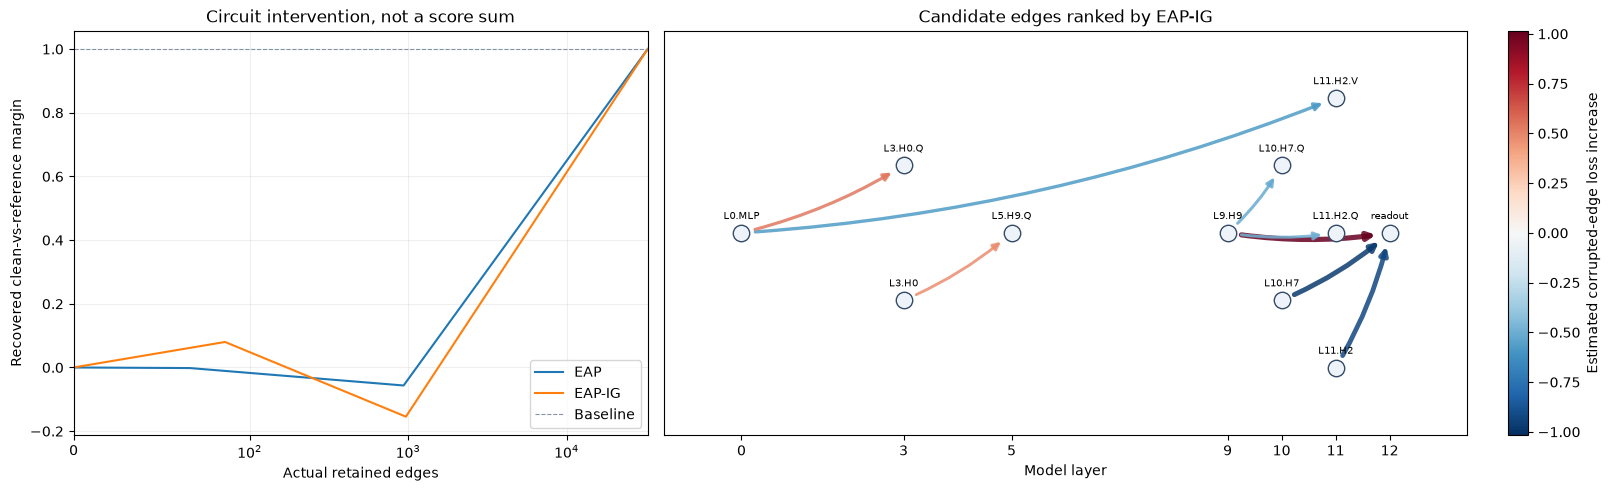

In [5]:
from vlmprobe.visualization import plot_connections

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), constrained_layout=True,
                         gridspec_kw={"width_ratios": [1, 1.4]})
curves = {}
for index, name in enumerate(evaluation.metadata["rankings"]):
    # Never plot a zero placeholder from an ineligible denominator as a failure.
    values = evaluation.tensors["faithfulness"][index, :, 0].clone()
    if not bool(evaluation.tensors["eligible"][0]):
        values[:] = float("nan")
    curves[name.upper().replace("_", "-")] = {
        "x": evaluation.tensors["retained_edges"][index], "y": values,
    }
if bool(evaluation.tensors["eligible"][0]):
    plot_intervention_curves(
        curves, ax=axes[0], baseline=1.0, xlabel="Actual retained edges",
        ylabel="Recovered clean-vs-reference margin", title="Circuit intervention, not a score sum",
    )
    axes[0].set_xscale("symlog", linthresh=100)
    axes[0].set_xlim(0, len(method.graph.edge_names))
else:
    axes[0].text(.5, .5, "Clean/reference margin too similar to normalize", ha="center")
    axes[0].set_axis_off()
# The graph draws only supplied high-scoring edges; it does not discover roles.
indices = attribution.tensors["edge_scores"].abs().topk(8).indices.tolist()
edges = []
for index in indices:
    u, v = method.graph.edge_indices[index].tolist()
    edges.append((method.graph.source_names[u], method.graph.destination_names[v],
                  float(attribution.tensors["edge_scores"][index])))
nodes = {node for source, receiver, _ in edges for node in (source, receiver)}
def layer_coordinate(node):
    if node == "input": return -1
    if node == "readout": return model.config.n_layer
    return int(node.split(".")[0][1:])
plot_connections(edges, node_layers={node: layer_coordinate(node) for node in nodes},
                 top_k=8, ax=axes[1], title="Candidate edges ranked by EAP-IG",
                 value_label="Estimated corrupted-edge loss increase")
for label in axes[1].texts:
    label.set_fontsize(7)
fig.savefig(output_dir / "causal-eap-ig.png", dpi=150, bbox_inches="tight")
plt.show()
